# Assignment 3: Paths, Reachability, and Connected Components Objective

# Starter Code

In [72]:
# upload graph
from google.colab import files
uploaded = files.upload()

Saving enron.txt to enron (1).txt


In [73]:
# Part 1: load the graph

import networkx as nx

def load_graph(file_path) -> nx.DiGraph:
  g = nx.read_weighted_edgelist(file_path)
  return g.to_directed()

g = load_graph("enron.txt")
g.nodes() # node IDs are strings

NodeView(('343111', '343112', '343113', '343114', '343115', '343116', '343117', '343118', '343119', '343130', '343120', '343121', '343122', '343123', '343124', '343169', '343125', '343126', '343127', '343128', '343129', '343132', '343133', '343134', '343136', '343137', '343138', '343139', '343140', '343141', '343143', '343144', '343145', '343146', '343147', '343148', '343149', '343150', '343151', '343152', '343153', '343154', '343155', '343156', '343158', '343159', '343160', '343161', '343162', '343163', '343164', '343165', '343166', '343167', '343168', '343170', '343171', '343172', '343174', '343175', '343176', '343177', '343178', '343179', '343180', '343181', '343182', '343183', '343185', '343186', '343187', '343188', '343189', '343190', '343191', '343193', '343194', '343195', '343196', '343197', '343198', '343199', '343200', '343201', '343202', '343203', '343204', '343205', '343206', '343207', '343184', '343208', '343209', '343210', '343211', '343212', '343213', '343214', '343215', 

In [74]:
# third column is edge attr

nx.get_edge_attributes(g, name='weight')

{('343111', '343112'): 1.0,
 ('343111', '343156'): 1.0,
 ('343111', '343164'): 1.0,
 ('343111', '343186'): 1.0,
 ('343111', '343196'): 1.0,
 ('343111', '343198'): 1.0,
 ('343111', '343233'): 1.0,
 ('343111', '343239'): 1.0,
 ('343111', '343247'): 1.0,
 ('343111', '343254'): 1.0,
 ('343111', '343130'): 0.0,
 ('343111', '343124'): 0.0,
 ('343111', '343159'): 0.0,
 ('343112', '343111'): 1.0,
 ('343112', '343114'): 1.0,
 ('343112', '343117'): 1.0,
 ('343112', '343140'): 1.0,
 ('343112', '343148'): 1.0,
 ('343112', '343203'): 1.0,
 ('343112', '343260'): 1.0,
 ('343112', '343128'): 0.0,
 ('343112', '343129'): 0.0,
 ('343112', '343198'): 0.0,
 ('343112', '343239'): 0.0,
 ('343112', '343177'): 0.0,
 ('343113', '343114'): 1.0,
 ('343114', '343113'): 1.0,
 ('343114', '343112'): 1.0,
 ('343114', '343127'): 1.0,
 ('343114', '343138'): 1.0,
 ('343114', '343165'): 1.0,
 ('343114', '343167'): 1.0,
 ('343114', '343182'): 1.0,
 ('343114', '343185'): 1.0,
 ('343114', '343190'): 1.0,
 ('343114', '343210'

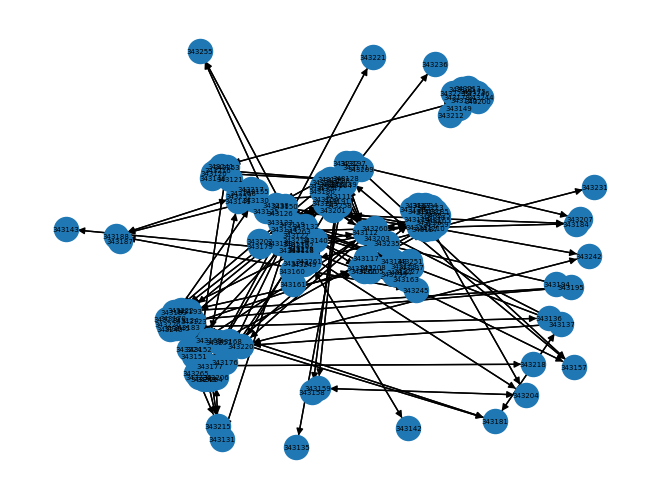

In [75]:
nx.draw(g, arrowsize=10,
        with_labels=True,
        font_size=5)

In [76]:
# Part 2: basic network information

def basic_network_info(G: nx.DiGraph):
  num_nodes = G.number_of_nodes()
  num_edges = G.number_of_edges()
  num_unique_sources = sum(1 for _, deg in g.out_degree() if deg > 0)

  return num_nodes, num_edges, num_unique_sources

print(basic_network_info(g))

(151, 512, 151)


In [77]:
# Part 3: Path analysis

# source 343231

# target 343261

def path_analysis(G: nx.DiGraph, source, target):
  has_path = nx.has_path(g, source, target)
  if has_path:
    # find path
    path = nx.shortest_path(g, source, target)
    # find path length
    length = nx.shortest_path_length(g, source, target)

    return path, length

  return f"No Path found from {source} -> {target}"



print(path_analysis(g, '343231', '343261'))

(['343231', '343261'], 1)


In [78]:
# Part 4: Strong connectivity

def strong_connectivity_analysis(G):
  # if graph is strongly connected
  is_strong_conn = nx.is_strongly_connected(G)
  # strongly connected components
  strong_comp = list(nx.strongly_connected_components(G))
  # number of strongly connected components
  len_strong_comp = nx.number_strongly_connected_components(G)
  # size of largest one
  max_comp = len(max(nx.strongly_connected_components(G), key=len))

  return is_strong_conn, len_strong_comp, max_comp

print(strong_connectivity_analysis(g))


(True, 1, 151)


In [79]:
# Part 5: Weak connectivity

def weak_connectivity_analysis(G):
  # if graph is weakly connected
  is_weak_conn = nx.is_weakly_connected(G)
  # number of weakly connected components
  len_weak_comp = nx.number_weakly_connected_components(G)
  # size of largest weakly connected component
  max_comp = len(max(nx.weakly_connected_components(G)))

  return is_weak_conn, len_weak_comp, max_comp

print(weak_connectivity_analysis(g))


(True, 1, 151)


# Part 1 - Load and Inspect the Network

In [89]:
print("Number of nodes:", g.number_of_nodes())
print("Number of edges:", g.number_of_edges())
print("Nodes:", list(g.nodes())[0:10])
print("Edges:", list(g.edges())[0:10])
print("Edge with attribute:", dict(list(nx.get_edge_attributes(g, name='weight').items())[0:10]))

Number of nodes: 151
Number of edges: 512
Nodes: ['343111', '343112', '343113', '343114', '343115', '343116', '343117', '343118', '343119', '343130']
Edges: [('343111', '343112'), ('343111', '343156'), ('343111', '343164'), ('343111', '343186'), ('343111', '343196'), ('343111', '343198'), ('343111', '343233'), ('343111', '343239'), ('343111', '343247'), ('343111', '343254')]
Edge with attribute: {('343111', '343112'): 1.0, ('343111', '343156'): 1.0, ('343111', '343164'): 1.0, ('343111', '343186'): 1.0, ('343111', '343196'): 1.0, ('343111', '343198'): 1.0, ('343111', '343233'): 1.0, ('343111', '343239'): 1.0, ('343111', '343247'): 1.0, ('343111', '343254'): 1.0}


1. There are 151 nodes in the graph.

2. There are 512 edges in the graph

3. One directed edge represents a communication relationship between two people.

4. Directed edge is appropriate for this dataset because the dataset showcases the relationships between people.

# Part 2 - Analyze Source Activity

In [81]:
# tuple showing, # of nodes, # of edges, and # of nodes with at least one outgoing edge

print(basic_network_info(g))

# get value at index 1 for each outdegree and find the max
print(max(g.out_degree(), key=lambda x: x[1]))


(151, 512, 151)
('343119', 20)


1. 151 unique nodes have at least one outgoing edge.

2. The node with the largest outdegree is node '343119' which has an outdegree of 20.

3. A large outdegree means that this person has communicated via email to 20 different people.

There are 151 unique nodes with at least one outgoing edge, this means that 151 people within the dataset have sent an email to at least one other person at the company.

# Part 3 - Directed Paths and Reachability

In [82]:
first_node = '343111'
second_node = '343224'

# from first -> second
res = path_analysis(g, first_node, second_node)
path = f'Path: {res[0]}'
length = f'Length: {res[1]}'
print(path, length)

# from second -> first
res2 = path_analysis(g, second_node, first_node)
path = f'Path: {res2[0]}'
length = f'Length: {res2[1]}'
print(path, length)

Path: ['343111', '343164', '343224'] Length: 2
Path: ['343224', '343164', '343111'] Length: 2


1. Each step in the communication network represents an email being sent from one employee to another.

2. Yes, a path exists in both directions.

3. Reachability differs depending on direction because there may be some nodes that doesn't have a directed outgoing edge back to the previous node.

# Part 4 - Strong Connectivity


In [83]:
is_strong, num_strong_comp, len_comp = strong_connectivity_analysis(g)
print("Network strongly connected:", is_strong)
print("Number of strongly connected components:", num_strong_comp)
print("Size of largest strongly connected component:", len_comp)

Network strongly connected: True
Number of strongly connected components: 1
Size of largest strongly connected component: 151


1. Yes
2. There is 1 strongly connected component
3. There are 151 nodes in the strongly connected component
4. For a group of nodes to belong to the same strongly connected component, this would mean that each node has to path to every other node. When in the context of communication flow, this would mean that the information can go through everyone in the network no matter how long the path is.

# Part 5 - Weak Connectivity

In [84]:
is_weak_conn, len_weak_comp, max_comp = weak_connectivity_analysis(g)

print('Network is weakly connected:', is_weak_conn)
print('Length of weakly connected components:', len_weak_comp)
print('Size of largest weakly connected component:', max_comp)

Network is weakly connected: True
Length of weakly connected components: 1
Size of largest weakly connected component: 151


1. Yes
2. There is 1 weakly connected component.
3. 151 nodes are in the largest weakly connected component
4. Weak connectivity means that there exists a path for each and every node to reach any other node regardless of direction. In this case, this would mean that the flow of information from one node would be able to flow to any other node regardless of direction.

# Part 6 - Compare Strong and Weak Connectivity

1. No, they are the same size.

2. They are the same size due to the fact that for 1 strongly connected component to exist, 1 weakly connected component must exist as well. Since the entire graph is just 1 strongly connected componenet, then the weakly connected component should exist since the main difference lies in the fact that a weakly connected component has no direction.

3. Regardless of direction, information is still able to flow to all nodes within this network.

4. Ignoring the direction will make networks appear more connected because an edge in an undirected graph can go in either direction which allows information to flow to more nodes.

# Part 7 - Additional Structural Observation

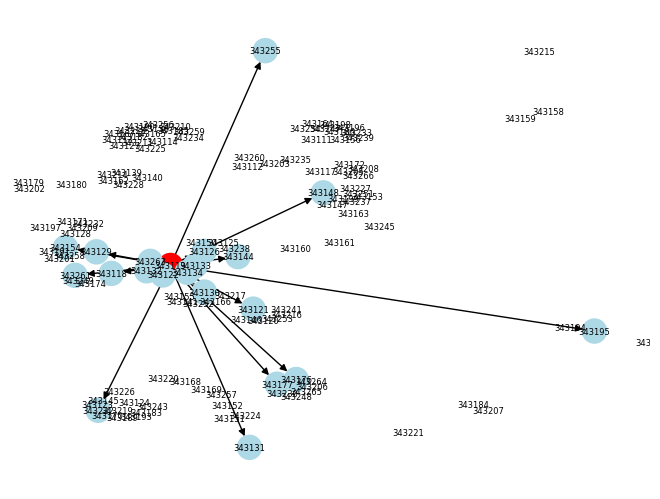

In [94]:
node = '343119'
e = [x[1] for x in g.out_edges(node)]
all_nodes = [node] + e

node_colors = ['red' if n == node else 'lightblue' for n in all_nodes]
pos = nx.spring_layout(g, seed=42)
nx.draw(g, pos=pos, nodelist=all_nodes, edgelist=list(g.out_edges(node)), with_labels=True, font_size=6, node_color=node_colors)

1. Node '343119' has an outdegree of 20 which is more than any other node in the graph.

2. Graph shown above

3. This means that the node '343119' has sent an outgoing email to 20 other employees at the company.  


# Part 8 - AI-Assisted Learning

1. how can i make a network graph so that it only shows the node 343119, the outgoing edges from this node, and the nodes that the outgoing edges connect to.

2. The AI recommended using a list comprehension to get the nodes that the out edges connect to in a list and to concatenate the node to the list for future use. It then showed me how to use this list in nodelist so that I can draw all of the nodes on a graph.

3. I verified the information by running the code and checking if the output was what I expected.

4. I used this suggestion and added on top of it by changing the color of the nodes and other styling choices for the graph.

# Part 9 - Reflection

Considering edge direction helped solidify the difference between strong connectivity and weak connectivity. I understood that components were but I did not understand the difference between weak and strong initially. But as I continued to work through the questions, it clicked that the main difference was whether or not the component was directed. Weak connectivity explicitly ignored direction while strong connectivity requires direction. I also learned that a weakly connected component is a requirement for a component to be strongly connected.